In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
import scienceplots
import matplotlib.ticker as mticker
import numpy as np

In [2]:
mpl.rcParams.update({
    "font.family": "Cambria",
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

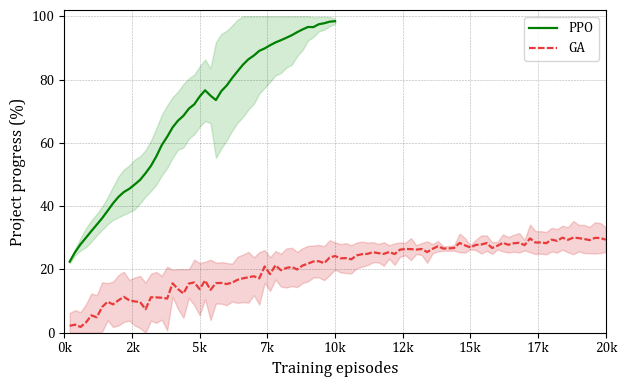

In [6]:
plt.figure(figsize=(6.4, 4.0))

#******************************************************************************************************
df_PPO = pd.read_csv("Data_PPO.csv", header=None, names=["Step", "EpRewMean1", "EpRewMean2", "EpRewMean3", "EpRewMean4", "EpRewMean5"
                                                     , "EpRewMean6", "EpRewMean7", "EpRewMean8", "EpRewMean9", "EpRewMean10"])

reward_cols = ["EpRewMean1", "EpRewMean2", "EpRewMean3", "EpRewMean4", "EpRewMean5", 
               "EpRewMean6", "EpRewMean7", "EpRewMean8", "EpRewMean9", "EpRewMean10"]

smoothed_runs = []

for col in reward_cols:
    #smoothed = df_PPO[col].rolling(1, min_periods=1).mean()
    smoothed = df_PPO[col]
    smoothed_runs.append(smoothed)

smoothed_runs = np.array(smoothed_runs)

df_PPO["smoothed_mean"] = smoothed_runs.mean(axis=0)
df_PPO["smoothed_std"] = smoothed_runs.std(axis=0, ddof=1)

plt.plot(df_PPO["Step"], df_PPO["smoothed_mean"], color="green", linewidth=1.6, label = "PPO")
plt.fill_between(df_PPO["Step"], 
                 df_PPO["smoothed_mean"] - df_PPO["smoothed_std"], 
                 np.clip(df_PPO["smoothed_mean"] + df_PPO["smoothed_std"], 0, 100), 
                 color="tab:green", alpha=0.2)
#******************************************************************************************************
df_GA = pd.read_csv("Data_GA.csv", header=None, names=["Step", "EpRewMean1", "EpRewMean2", "EpRewMean3", "EpRewMean4", "EpRewMean5"
                                                     , "EpRewMean6", "EpRewMean7", "EpRewMean8", "EpRewMean9", "EpRewMean10"])

reward_cols = ["EpRewMean1", "EpRewMean2", "EpRewMean3", "EpRewMean4", "EpRewMean5", 
               "EpRewMean6", "EpRewMean7", "EpRewMean8", "EpRewMean9", "EpRewMean10"]

smoothed_runs = []

for col in reward_cols:
    #smoothed = df_GA[col].rolling(1, min_periods=1).mean()
    smoothed = df_GA[col]
    smoothed_runs.append(smoothed)

smoothed_runs = np.array(smoothed_runs)

df_GA["smoothed_mean"] = smoothed_runs.mean(axis=0)
df_GA["smoothed_std"] = smoothed_runs.std(axis=0, ddof=1)

plt.plot(df_GA["Step"], df_GA["smoothed_mean"], color="#e93a3a", linewidth=1.6, label = "GA", linestyle="--", dashes=(3,1))
plt.fill_between(df_GA["Step"], 
                 np.clip(df_GA["smoothed_mean"] - df_GA["smoothed_std"], 0, 100), 
                 df_GA["smoothed_mean"] + df_GA["smoothed_std"], 
                 color="tab:red", alpha=0.2)
#******************************************************************************************************


#plt.title("Average over 10 different seeds", pad=8, fontsize=11)


plt.xlabel("Training episodes", fontsize=12)
plt.ylabel("Project progress (%)", fontsize=12)
plt.grid(True, color='black', linestyle='--', linewidth=0.4, alpha=0.3)

# --- Set x‑axis minimum at 0 ---
plt.xlim(left=0, right=20000)
plt.ylim(bottom=0, top=102)
# → horizontal line at y = 0
#plt.axhline(y=0, color='black', linewidth=0.8)

# --- Format x‑axis ticks as 50k, 100k, 150k, etc. ---
plt.gca().xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x/1000)}k"))


plt.legend(frameon=True, fontsize=10)




plt.tight_layout()
plt.savefig("Fig11_new_Springer.png", dpi=600, bbox_inches='tight')
plt.show()